<h1> Loading data <h1>

In [ ]:
from v3_1 import CloudDataManager

manager = CloudDataManager()
filepath = "/workspaces/TDA-workspace/data/Point clouds-selected/control name=embryo_3.csv"
filepath2 = "/workspaces/TDA-workspace/data/Point clouds-selected/epha2a hom name=embryo_4.csv"
# filepath3 = "/workspaces/TDA-workspace/data/Point clouds-selected/control WT  full video centroids_table name=embryo_1.csv"
ids = manager.load_group_from_file(filepath)
ids2 = manager.load_group_from_file(filepath2)
# ids3 = manager.load_group_from_file(filepath3)
# display answers in a table for 10 by 6
print("Loaded IDs:")
for i, id in enumerate([*ids, *ids2]):
    print(f"{id}", end=" \t")
    if (i + 1) % 5 == 0:
        print()  # New line after every 5 IDs

ModuleNotFoundError: No module named 'tda_module_v3_1'

<h2> Checking data Structure <h2>

In [15]:
# manager.groups[("embryo_3", 50)]


<h3> Calculating Diagrams and Landscapes <h3>

In [16]:
# help(manager.TDA.compute_all_persistence_diagrams)
# help(manager.TDA.compute_all_persistence_landscapes)
manager.TDA.compute_all_persistence_diagrams()
manager.TDA.compute_all_persistence_landscapes(n_layers=2,resolution=500)
manager._tda_params


{'max_dimension': 2,
 'max_edge_length': inf,
 'homology_coeff_field': 2,
 'min_persistence': 0.0,
 'dimensions': [0, 1],
 'resolution': 500,
 'n_layers': 2}

<h3> Persistance Diagramsn and Landscape Plots <h3>

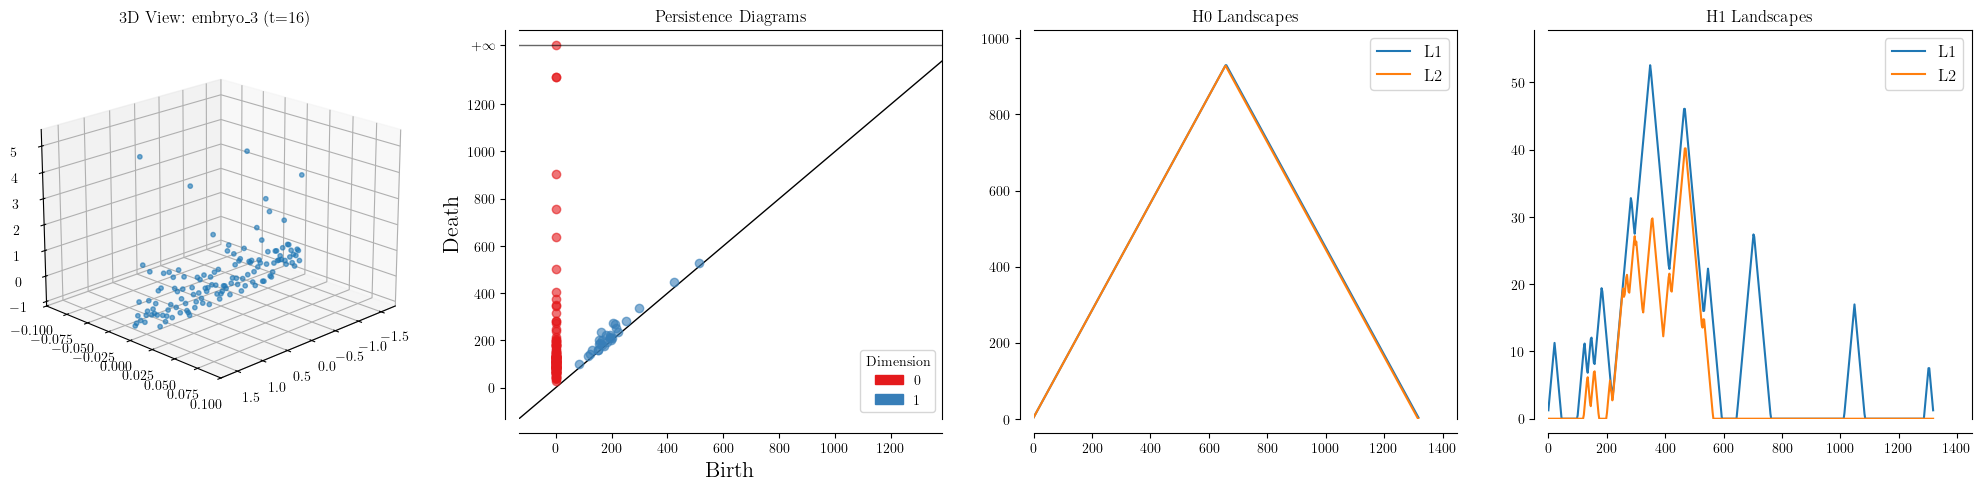

In [17]:
manager.Plotter.compare_tda_summaries([("embryo_3", 16)], shared_axes=False)

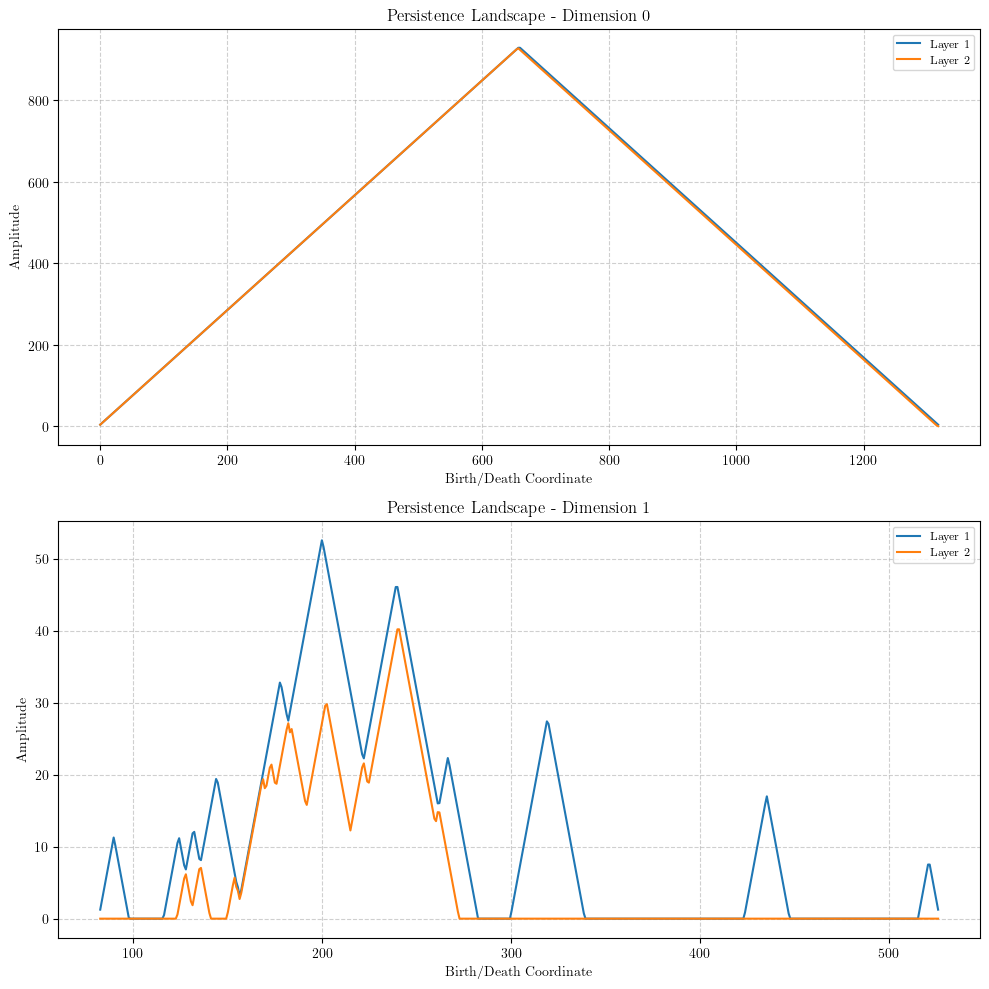

In [18]:
fig = manager.Plotter.plot_persistence_landscapes(manager.groups[("embryo_3",16)].landscapes, )
fig

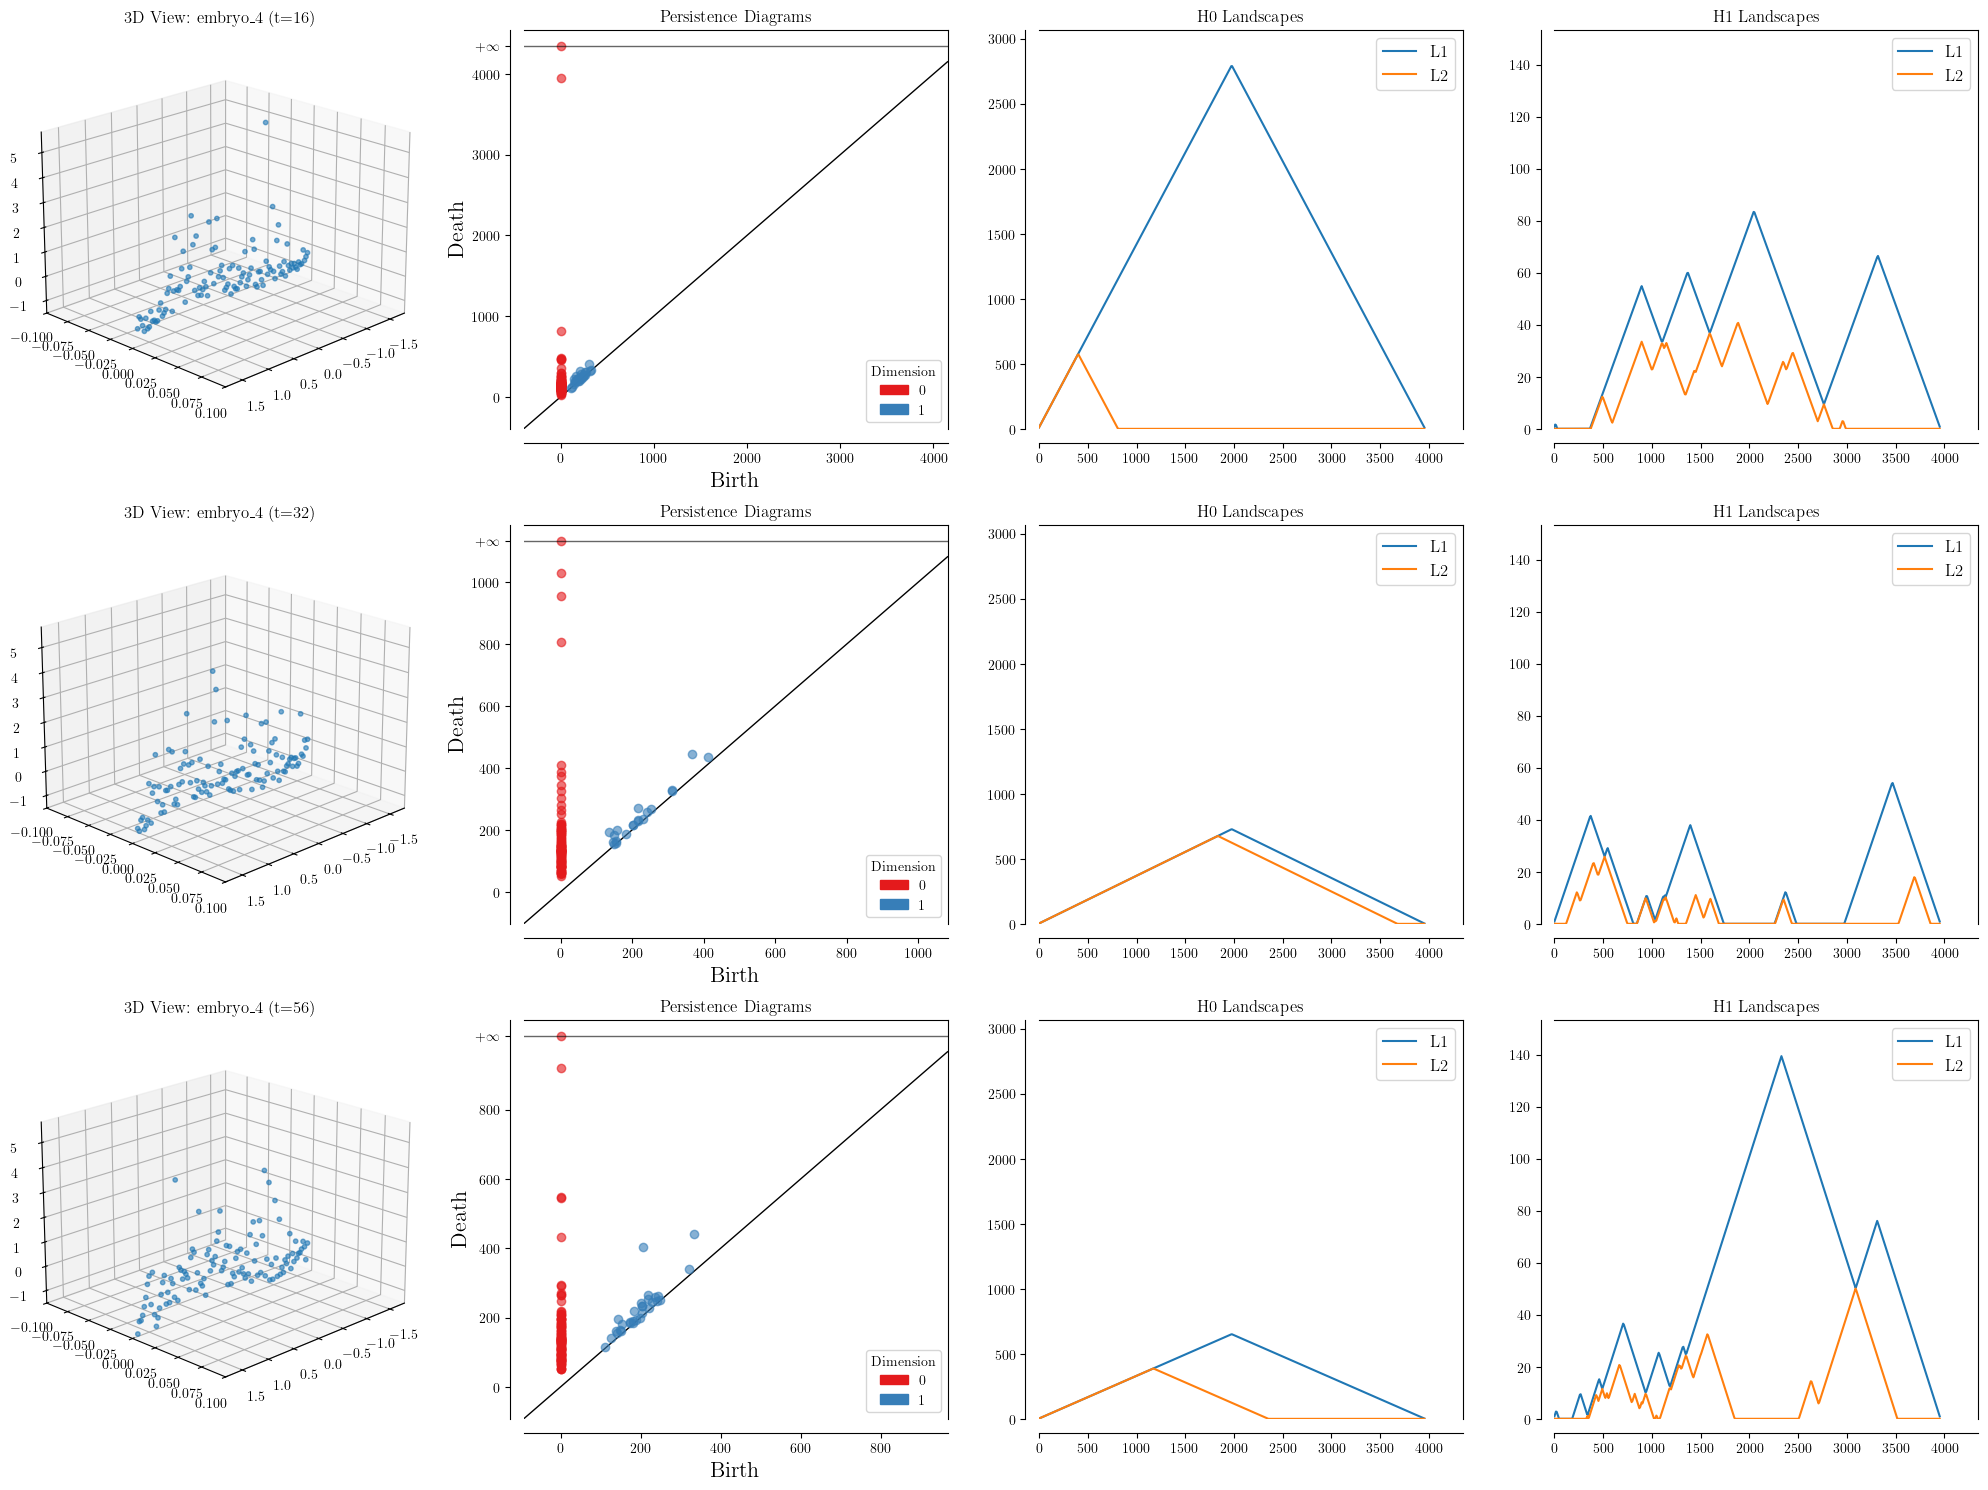

In [19]:
fig = manager.Plotter.compare_tda_summaries([("embryo_4",16), ("embryo_4",32), ("embryo_4",56)], shared_axes=False)
fig

<h2> PCA Analsys <h2>

In [20]:
# Run PCA on H0 and H1 Combined
manager.PCA.run(properties=[0,1])
# Run PCA on H0 only
manager.PCA.run(properties=[0])
# Run PCA on H1 only
manager.PCA.run(properties=[1])
# Print the results of the PCA on H0 and H1 Combined with 2 components
print("Run PCA on H0 and H1 Combined with 2 components")
print(f"Explained Variance Ratio for H0 and H1 Combined: {[f'{s:.3f}' for s in manager.PCA.results[("All", "All", (0, 1))]['explained_variance_ratio']]}")
print(f"Components for H0 and H1 Combined: {manager.PCA.results[("All", "All", (0, 1))]['components']}")
# Print the results of the PCA on H0 only with 2 components
print("Run PCA on H0 only with 2 components")
print(f"Explained Variance Ratio for H0 only: {[f'{s:.3f}' for s in manager.PCA.results[("All", "All", (0,))]['explained_variance_ratio']]}")
print(f"Components for H0 only: {manager.PCA.results[("All", "All", (0,))]['components']}")
# Print the results of the PCA on H1 only with 2 components
print("Run PCA on H1 only with 2 components")
print(f"Explained Variance Ratio for H1 only: {[f'{s:.3f}' for s in manager.PCA.results[("All", "All", (1,))]['explained_variance_ratio']]}")
print(f"Components for H1 only: {manager.PCA.results[("All", "All", (1,))]['components']}")

Run PCA on H0 and H1 Combined with 2 components
Explained Variance Ratio for H0 and H1 Combined: ['0.642', '0.267']
Components for H0 and H1 Combined: [[ 0.03747145  0.03747145  0.03760139 ...  0.00844772  0.00844772
   0.        ]
 [-0.01600121 -0.01600121 -0.01550403 ...  0.04116502  0.04116502
  -0.        ]]
Run PCA on H0 only with 2 components
Explained Variance Ratio for H0 only: ['0.633', '0.235']
Components for H0 only: [[ 0.03875439  0.03875439  0.03875439 ... -0.00879801 -0.00879801
  -0.        ]
 [ 0.01447956  0.01447956  0.01447956 ...  0.04636026  0.04636026
   0.        ]]
Run PCA on H1 only with 2 components
Explained Variance Ratio for H1 only: ['0.262', '0.159']
Components for H1 only: [[-0.03365877 -0.03365877 -0.02311194 ...  0.          0.
   0.        ]
 [ 0.0060079   0.0060079   0.00744902 ...  0.          0.
   0.        ]]


{np.float64(64.16846901118983), np.float64(26.694428745873044)}


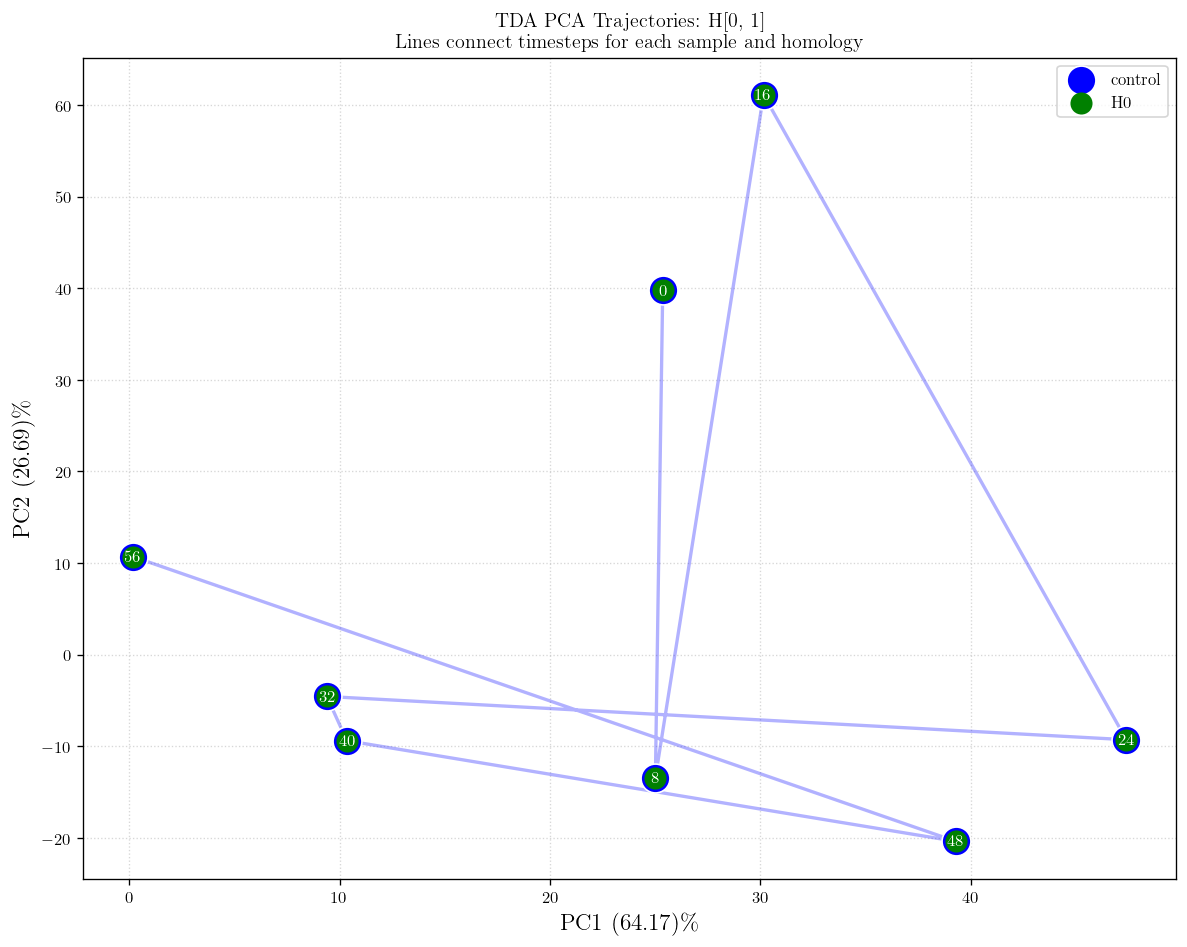

In [21]:
manager.PCA.plot_trajectories(properties=[0,1], do_not_include={"properties":[1],"condition":["epha2a"]})   

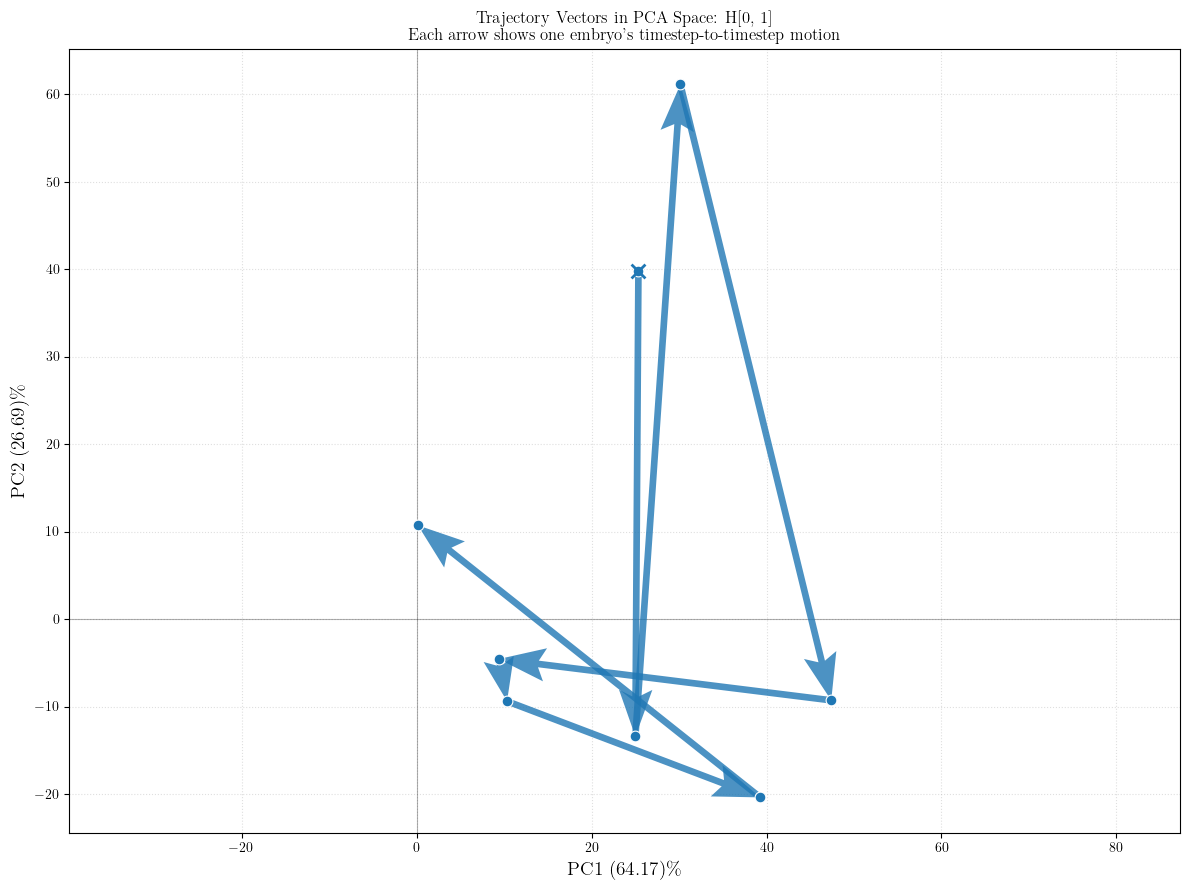

In [22]:
manager.PCA.plot_trajectory_vectors(properties=[0,1], do_not_include={"properties":[1], "condition":["epha2a"],"embryo_names":[""]})



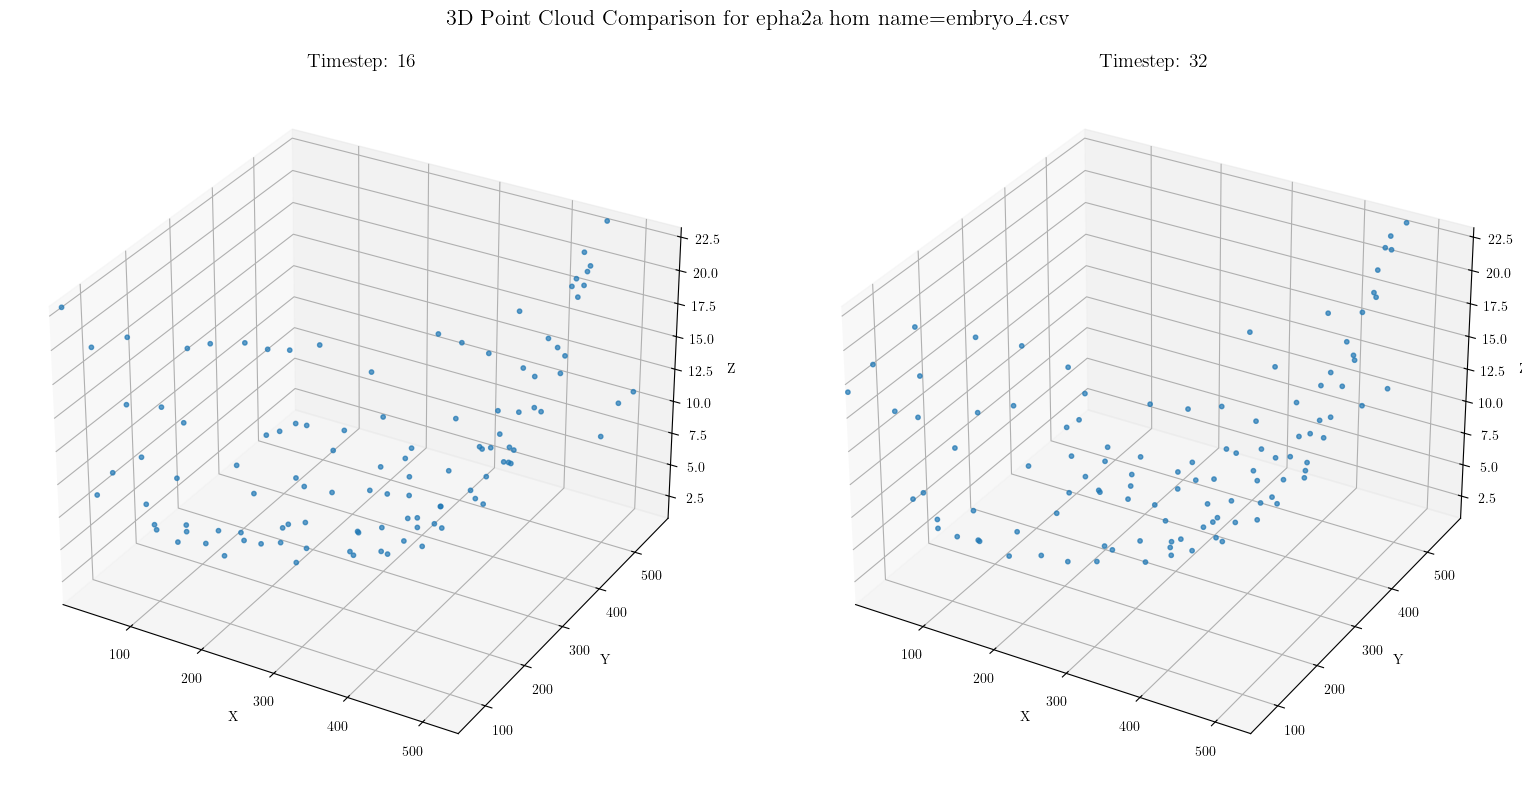

In [23]:
import os
import pandas as pd
import matplotlib.pyplot as plt
def visualize_point_clouds_side_by_side(file_path: str, ts1: int, ts2: int):
    """
    Generates side-by-side 3D scatter plots for two timesteps from the same file.
    
    Args:
        file_path: The absolute path to the CSV file.
        ts1: The first timestep to plot.
        ts2: The second timestep to plot.
    """
    if not os.path.exists(file_path):
        print(f"Error: File not found at {file_path}")
        return

    try:
        df = pd.read_csv(file_path)
        
        # --- Prepare Data ---
        df = df.rename(columns={
            "Center of the object_0": "x",
            "Center of the object_1": "y",
            "Center of the object_2": "z",
        })
        
        data1 = df[df['timestep'] == ts1]
        data2 = df[df['timestep'] == ts2]

        if data1.empty or data2.empty:
            print(f"Error: Data for one or both timesteps ({ts1}, {ts2}) not found.")
            return

        # --- Create Plot ---
        fig = plt.figure(figsize=(16, 8))
        fig.suptitle(f"3D Point Cloud Comparison for {os.path.basename(file_path)}", fontsize=16)

        # --- First Subplot ---
        ax1 = fig.add_subplot(1, 2, 1, projection='3d')
        ax1.scatter(data1['x'], data1['y'], data1['z'], s=10, alpha=0.7)
        ax1.set_title(f"Timestep: {ts1}", fontsize=14)
        ax1.set_xlabel("X")
        ax1.set_ylabel("Y")
        ax1.set_zlabel("Z")

        # --- Second Subplot ---
        ax2 = fig.add_subplot(1, 2, 2, projection='3d')
        ax2.scatter(data2['x'], data2['y'], data2['z'], s=10, alpha=0.7)
        ax2.set_title(f"Timestep: {ts2}", fontsize=14)
        ax2.set_xlabel("X")
        ax2.set_ylabel("Y")
        ax2.set_zlabel("Z")
        
        # --- Synchronize Axes for Direct Comparison ---
        # Find global min/max across both datasets to set shared axis limits
        x_min = min(data1['x'].min(), data2['x'].min())
        x_max = max(data1['x'].max(), data2['x'].max())
        y_min = min(data1['y'].min(), data2['y'].min())
        y_max = max(data1['y'].max(), data2['y'].max())
        z_min = min(data1['z'].min(), data2['z'].min())
        z_max = max(data1['z'].max(), data2['z'].max())

        ax1.set_xlim(x_min, x_max)
        ax1.set_ylim(y_min, y_max)
        ax1.set_zlim(z_min, z_max)
        
        ax2.set_xlim(x_min, x_max)
        ax2.set_ylim(y_min, y_max)
        ax2.set_zlim(z_min, z_max)

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

    except Exception as e:
        print(f"An unexpected error occurred: {e}")

if __name__ == "__main__":
    target_file = '/workspaces/TDA-workspace/data/Point clouds-selected/epha2a hom name=embryo_4.csv'
    
    # Visualize the two timesteps of interest
    visualize_point_clouds_side_by_side(target_file, ts1=16, ts2=32)

<h1> 